<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/9%EC%A3%BC%EC%B0%A8/LSTM%EC%9D%84_%EC%9D%B4%EC%9A%A9%ED%95%9C_%EC%A3%BC%EA%B0%80_%EC%98%88%EC%B8%A1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install finance-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]


In [2]:
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM


In [3]:
# (2) 데이터셋 로드: 삼성전자(005930), 2016년 이후
samsung = fdr.DataReader('005930', '2016')
print(samsung)

openValues = samsung[['Open']]  # 시작가(Open)만 사용

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  194400  187000  194100   8640037  0.003101

[2660 rows x 6 columns]


In [4]:
# (3) 특징값 정규화: 0~1 사이로 변환
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(openValues)

In [5]:
# (4) 훈련 데이터와 테스트 데이터 분리: 뒤쪽 200개가 테스트
TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]

In [6]:
# (5) 순차 훈련 데이터 생성
# 슬라이딩 윈도우 방식을 사용했고 window 가 30으로 해서 동작하게 된다
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data) - window):
        train.append(data[i:i + window])
        target.append(data[i + window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)

In [7]:
# (6) LSTM 구축
# 다음 날 시가라는 숫자 하나를 예측하는 회귀 문제라서 Dense(1)
model = Sequential()
model.add(LSTM(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False)
          )
model.add(Dense(1))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
# (7) 모델 학습
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0017
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 7.2981e-05
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.0595e-05
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.8577e-05
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.9039e-05
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.7706e-05
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.9933e-05
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.3755e-05
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.6567e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.4383e-05
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.4369e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 5.4476e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 5.3968e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 5.

In [9]:
# (8) 테스트셋으로 미래 주가 예측
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


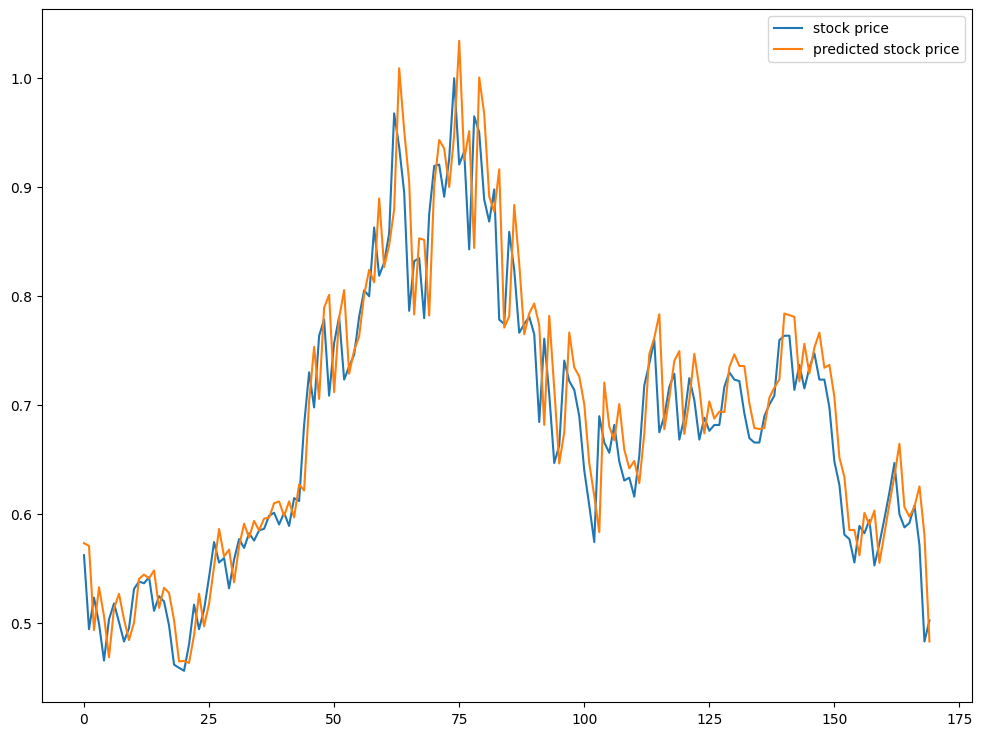

In [10]:
# (9) 그래프 그리기
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()